## Design a Bayes’ classifier from scratch!

1. Get images of forest and urban landscapes (if needed hand-craft
the areas so that it only has pixels of one type).
2. Plot their respective histograms and find parametric models for
their PDFs → find these parameters
3. Given a new image pass each of its pixels through the Bayes test
to decide if its forest or urban. Color it red or blue accordingly
4. Explain all steps and show the results

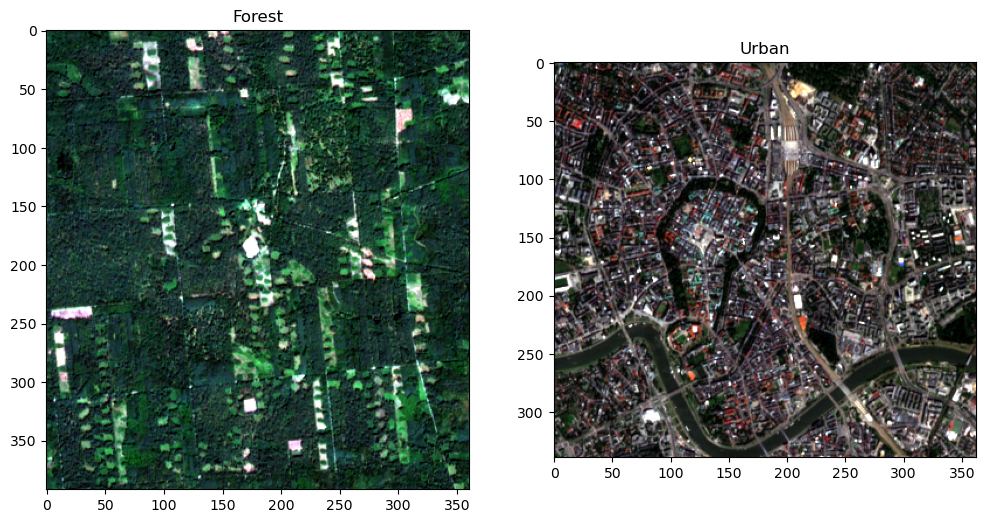

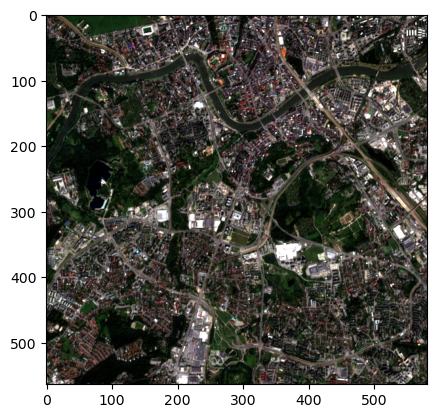

In [59]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib.patches import Patch
from scipy import stats

DATA = Path("./scenes")

S2_BANDS = ["B02", "B03", "B04"]
S2_BANDS.reverse()

S2_BAND_NAMES = {
    "B02": "Blue",
    "B03": "Green",
    "B04": "Red",
}

S2_BAND_COLORS = {
    "B04": "red",
    "B03": "green",
    "B02": "blue",
}


def percentile_stretch(array: np.ndarray, lower_percentile: int = 1, upper_percentile: int = 99):
    p_low, p_high = np.percentile(array, (lower_percentile, upper_percentile))
    clipped = np.clip(array, p_low, p_high)
    return (clipped - p_low) / (p_high - p_low)


def get_raster_image(filename: str) -> np.ndarray:
    image_bands = []
    for band in S2_BANDS:
        with rasterio.open(DATA / f"{filename}_{band}.tif") as src:
            image_bands.append(src.read(1).astype(np.float32) / 10000.0)
    return np.dstack(image_bands)


def to_rgb(image: np.ndarray) -> np.ndarray:
    return np.dstack([percentile_stretch(image[:, :, i]) for i in range(image.shape[-1])])


def display_raster_image(first_image: np.ndarray, second_image: np.ndarray, first_title: str = "", second_title: str = ""):
    _, ax = plt.subplots(1, 2, figsize=(12, 12))
    ax[0].imshow(to_rgb(first_image))
    ax[1].imshow(to_rgb(second_image))
    ax[0].set_title(first_title)
    ax[1].set_title(second_title)
    plt.show()


def compare(image: np.ndarray, preds: np.ndarray, title: str = ""):
    legend = [
        Patch(facecolor="blue", label="Forest"),
        Patch(facecolor="red", label="Urban"),
    ]
    rgb = to_rgb(image)
    _, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(rgb)
    ax[0].set_title("RGB")

    ax[1].imshow(preds, cmap="bwr", vmin=0, vmax=1)
    ax[1].set_title("Prediction" + (f" ({title})" if title else ""))
    ax[1].legend(handles=legend, loc="upper right")

    ax[2].imshow(rgb)
    ax[2].imshow(preds, cmap="bwr", vmin=0, vmax=1, alpha=0.35)
    ax[2].set_title("Overlay")
    ax[2].legend(handles=legend, loc="upper right")

    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()


s2_forest = get_raster_image("s2_forest")
s2_urban = get_raster_image("s2_urban")
s2_mixed = get_raster_image("s2_mixed")

display_raster_image(s2_forest, s2_urban, "Forest", "Urban")

plt.imshow(to_rgb(s2_mixed))

In [60]:
import math

def get_means_and_stds(image: np.ndarray):
    return [image[:,:,i].mean() for i in range(0,3)], [image[:,:,i].std() for i in range(0,3)]

def gaussian_height(mju: float, sigma: float, x: float):
    return 1 / (math.sqrt(2 * math.pi) * sigma) * math.exp(-pow((x - mju), 2) / (2 * pow(sigma, 2)))


f_means, f_stds = get_means_and_stds(s2_forest)
u_means, u_stds = get_means_and_stds(s2_urban)

print(f_means, f_stds)
print(u_means, u_stds)

[np.float32(0.12265043), np.float32(0.13502689), np.float32(0.12302686)] [np.float32(0.012118095), np.float32(0.009237887), np.float32(0.0061025457)]
[np.float32(0.17782654), np.float32(0.17709436), np.float32(0.16498385)] [np.float32(0.048883658), np.float32(0.042844716), np.float32(0.04007083)]


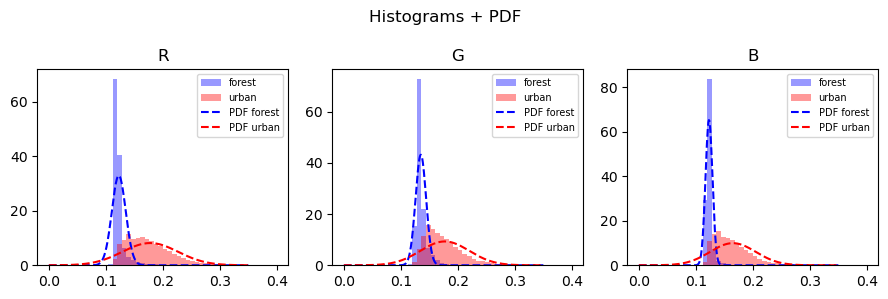

In [61]:
xs = np.linspace(0, 0.35, 400)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))

for i, name in enumerate(["R", "G", "B"]):
    ax = axes[i]
    ax.hist(s2_forest[:,:,i].ravel(), bins=50, range=(0, 0.4), density=True, alpha=0.4, color="blue", label="forest")
    ax.hist(s2_urban[:,:,i].ravel(), bins=50, range=(0, 0.4), density=True, alpha=0.4, color="red", label="urban")
    ax.plot(xs, [gaussian_height(f_means[i], f_stds[i], x) for x in xs], "b--", label="PDF forest")
    ax.plot(xs, [gaussian_height(u_means[i], u_stds[i], x) for x in xs], "r--", label="PDF urban")
    ax.set_title(name); ax.legend(fontsize=7)

plt.suptitle("Histograms + PDF"); plt.tight_layout(); plt.show()

In [62]:
def predict_single(f_means: [float], f_stds: [float], u_means: [float], u_stds: [float], pixel: np.ndarray):
    r,g,b = pixel
    score_forest = gaussian_height(f_means[0], f_stds[0], r) * gaussian_height(f_means[1], f_stds[1], g) * gaussian_height(f_means[2], f_stds[2], b)
    score_urban = gaussian_height(u_means[0], u_stds[0], r) * gaussian_height(u_means[1], u_stds[1], g) * gaussian_height(u_means[2], u_stds[2], b)
    return 1 if score_urban > score_forest else 0

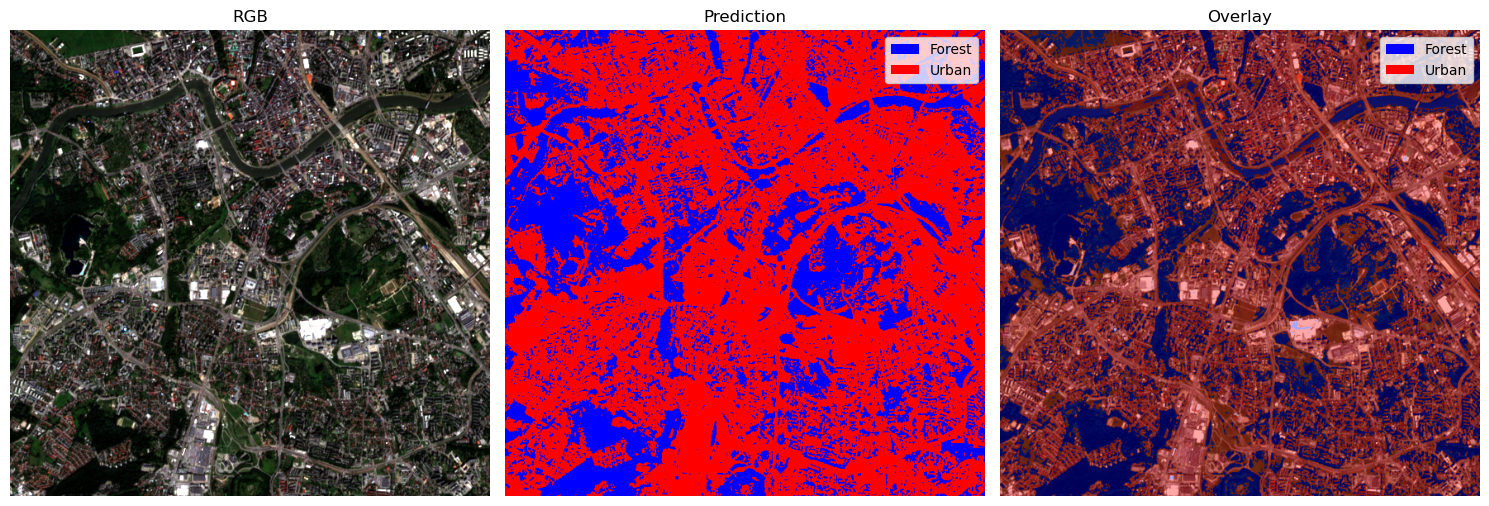

In [63]:
preds = np.array([predict_single(f_means, f_stds, u_means, u_stds, pixel) for pixel in s2_mixed.reshape(-1, 3)])

compare(s2_mixed, preds.reshape(s2_mixed.shape[:2]))

## Conclusions
In my opinion, in this case Bayes performed much better and it is clearly visible on the comparison figure. It catched the urban features much better than kNN model. On this dataset Bayes is much more sensitive and catches even small patches of forestry / plants. Bayes' model flagged part of the Vistula river as a Forest class. We don't differentiate the river as a seperate class however it is worth noticing because in kNN model Vistula was classified as urban class. I am much more content with the result obtained with Bayes method, it appeared more effective in my case and on my data.